In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

display(df.head())

print("\nTipos de datos:")
print(df.dtypes)

Filas: 7043
Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Tipos de datos:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [3]:
print("Primeros 15 valores:")
print(df["TotalCharges"].head(15).to_list())
vacios = df["TotalCharges"].str.strip().eq("")
print("\nCantidad de valores vacios o con espacios:")
print(vacios.sum())
print("\nFilas con TotalCharges vacio:")
display(df.loc[vacios, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

Primeros 15 valores:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8', '5681.1', '5036.3', '2686.05']

Cantidad de valores vacios o con espacios:
11

Filas con TotalCharges vacio:


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [5]:
# Contar clientes con antigüedad igual a cero
print("Clientes con tenure = 0:", (df["tenure"] == 0).sum())

# Comparar sus valores de TotalCharges y Churn
clientes_nuevos = df.loc[
    df["tenure"] == 0,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]
]

display(clientes_nuevos)

# Revisar cómo se distribuye Churn entre estos clientes
print("\nDistribución de Churn:")
print(clientes_nuevos["Churn"].value_counts(dropna=False))

Clientes con tenure = 0: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No



Distribución de Churn:
Churn
No    11
Name: count, dtype: int64


In [6]:
# 1. Contar valores faltantes por columna
print("=== VALORES FALTANTES ===")
print(df.isna().sum())

# 2. Contar cadenas vacías o con espacios
print("\n=== CADENAS VACÍAS ===")
for col in df.select_dtypes(include=["str", "object"]).columns:
    cantidad = df[col].str.strip().eq("").sum()
    if cantidad > 0:
        print(f"{col}: {cantidad}")

# 3. Comprobar filas duplicadas completas
print("\n=== FILAS DUPLICADAS ===")
print("Filas duplicadas:", df.duplicated().sum())

# 4. Comprobar identificadores de cliente repetidos
print("\n=== CUSTOMERID REPETIDOS ===")
print("Identificadores repetidos:", df["customerID"].duplicated().sum())

=== VALORES FALTANTES ===
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

=== CADENAS VACÍAS ===
TotalCharges: 11

=== FILAS DUPLICADAS ===
Filas duplicadas: 0

=== CUSTOMERID REPETIDOS ===
Identificadores repetidos: 0


In [7]:
# Intentar convertir TotalCharges a números sin modificar el DataFrame original
total_charges_num = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")

# Identificar los valores que no pudieron convertirse
no_convertibles = total_charges_num.isna()

print("=== CONVERSIÓN DE TOTALCHARGES ===")
print("Total de registros:", len(df))
print("Valores convertibles:", total_charges_num.notna().sum())
print("Valores no convertibles:", no_convertibles.sum())

print("\n=== REGISTROS NO CONVERTIBLES ===")
display(
    df.loc[
        no_convertibles,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]
    ]
)

print("\n=== RESUMEN DE LOS CARGOS CONVERTIBLES ===")
print(total_charges_num.describe())

=== CONVERSIÓN DE TOTALCHARGES ===
Total de registros: 7043
Valores convertibles: 7032
Valores no convertibles: 11

=== REGISTROS NO CONVERTIBLES ===


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No



=== RESUMEN DE LOS CARGOS CONVERTIBLES ===
count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64


In [8]:
# Crear una copia para trabajar de forma segura
df_clean = df.copy()

# Convertir TotalCharges a formato numérico
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].str.strip(),
    errors="coerce"
)

# Verificar que los valores vacíos correspondan a clientes con tenure = 0
mascara_vacios = df_clean["TotalCharges"].isna()

print("Valores vacíos antes del tratamiento:", mascara_vacios.sum())
print(
    "Valores vacíos con tenure distinto de 0:",
    ((df_clean["tenure"] != 0) & mascara_vacios).sum()
)

# Reemplazar por 0 solo los cargos vacíos de clientes con tenure = 0
mascara_corregir = mascara_vacios & (df_clean["tenure"] == 0)
df_clean.loc[mascara_corregir, "TotalCharges"] = 0

# Comprobar el resultado
print("\n=== RESULTADO DE LA LIMPIEZA ===")
print("Filas:", df_clean.shape[0])
print("Columnas:", df_clean.shape[1])
print("Valores vacíos en TotalCharges:", df_clean["TotalCharges"].isna().sum())
print("Tipo de TotalCharges:", df_clean["TotalCharges"].dtype)
print("Clientes con tenure = 0:", (df_clean["tenure"] == 0).sum())

display(
    df_clean.loc[
        df_clean["tenure"] == 0,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

Valores vacíos antes del tratamiento: 11
Valores vacíos con tenure distinto de 0: 0

=== RESULTADO DE LA LIMPIEZA ===
Filas: 7043
Columnas: 21
Valores vacíos en TotalCharges: 0
Tipo de TotalCharges: float64
Clientes con tenure = 0: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,0.0,No
753,3115-CZMZD,0,20.25,0.0,No
936,5709-LVOEQ,0,80.85,0.0,No
1082,4367-NUYAO,0,25.75,0.0,No
1340,1371-DWPAZ,0,56.05,0.0,No
3331,7644-OMVMY,0,19.85,0.0,No
3826,3213-VVOLG,0,25.35,0.0,No
4380,2520-SGTTA,0,20.00,0.0,No
5218,2923-ARZLG,0,19.70,0.0,No
6670,4075-WKNIU,0,73.35,0.0,No


=== DISTRIBUCIÓN DE CHURN ===
Churn
No     5174
Yes    1869
Name: count, dtype: int64

=== PORCENTAJE DE CLIENTES ===
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Tasa de abandono: 26.54%


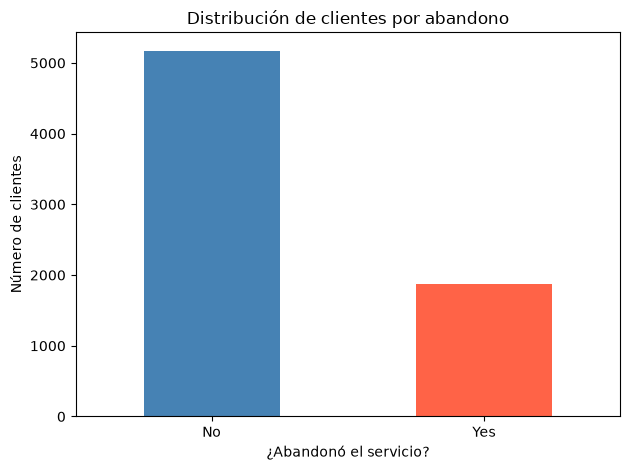

In [9]:
# 1. Contar clientes por estado de abandono
print("=== DISTRIBUCIÓN DE CHURN ===")
conteo_churn = df_clean["Churn"].value_counts()
print(conteo_churn)

# 2. Calcular porcentajes
print("\n=== PORCENTAJE DE CLIENTES ===")
porcentaje_churn = df_clean["Churn"].value_counts(normalize=True) * 100
print(porcentaje_churn.round(2))

# 3. Calcular la tasa de abandono
tasa_abandono = (df_clean["Churn"] == "Yes").mean() * 100
print(f"\nTasa de abandono: {tasa_abandono:.2f}%")

# 4. Visualizar la distribución
import matplotlib.pyplot as plt

conteo_churn.plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Distribución de clientes por abandono")
plt.xlabel("¿Abandonó el servicio?")
plt.ylabel("Número de clientes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

=== TASA DE ABANDONO POR CONTRATO ===
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


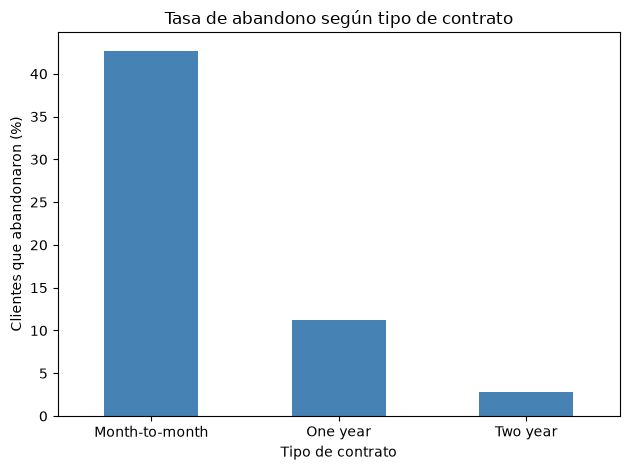

In [10]:
# Calcular el porcentaje de abandono dentro de cada tipo de contrato
churn_contrato = (
    df_clean.groupby("Contract", observed=True)["Churn"]
    .apply(lambda grupo: (grupo == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("=== TASA DE ABANDONO POR CONTRATO ===")
print(churn_contrato.round(2))

# Crear gráfico
ax = churn_contrato.plot(kind="bar", color="steelblue")

ax.set_title("Tasa de abandono según tipo de contrato")
ax.set_xlabel("Tipo de contrato")
ax.set_ylabel("Clientes que abandonaron (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

=== TASA DE ABANDONO POR ANTIGÜEDAD ===
TenureGroup
0-12 meses         47.44
13-24 meses        28.71
25-48 meses        20.39
49-60 meses        14.42
Más de 60 meses     6.61
Name: Churn, dtype: float64


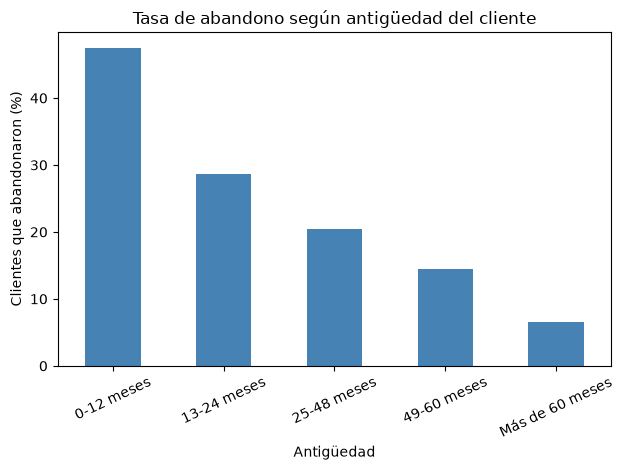

In [11]:
# Crear grupos de antigüedad en meses
df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 60, float("inf")],
    labels=[
        "0-12 meses",
        "13-24 meses",
        "25-48 meses",
        "49-60 meses",
        "Más de 60 meses"
    ]
)

# Calcular la tasa de abandono dentro de cada grupo
churn_antiguedad = (
    df_clean.groupby("TenureGroup", observed=False)["Churn"]
    .apply(lambda grupo: (grupo == "Yes").mean() * 100)
)

print("=== TASA DE ABANDONO POR ANTIGÜEDAD ===")
print(churn_antiguedad.round(2))

# Graficar resultados
ax = churn_antiguedad.plot(kind="bar", color="steelblue")
ax.set_title("Tasa de abandono según antigüedad del cliente")
ax.set_xlabel("Antigüedad")
ax.set_ylabel("Clientes que abandonaron (%)")
ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

=== TASA DE ABANDONO: CONTRATO VS. ANTIGÜEDAD (%) ===


Contract,Month-to-month,One year,Two year
TenureGroup,,,
0-12 meses,51.35,10.48,0.00
13-24 meses,37.72,8.12,0.00
25-48 meses,32.92,10.62,2.19
49-60 meses,27.78,13.71,3.97
Más de 60 meses,22.22,12.14,3.14


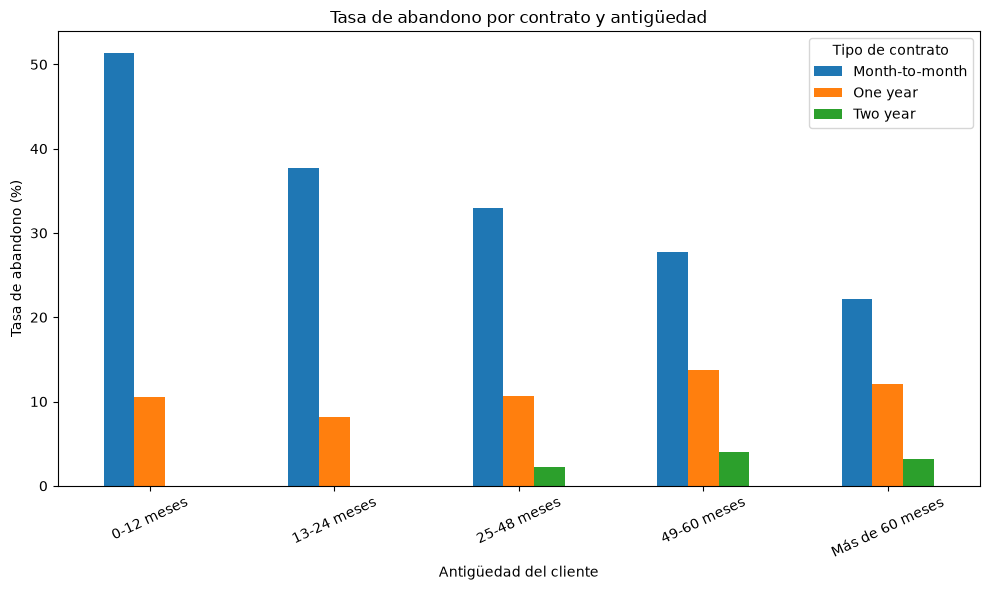

In [12]:
# Crear una tabla con la tasa de abandono por contrato y antigüedad
tabla_churn = pd.pivot_table(
    df_clean,
    values="Churn",
    index="TenureGroup",
    columns="Contract",
    aggfunc=lambda grupo: (grupo == "Yes").mean() * 100,
    observed=False
)

print("=== TASA DE ABANDONO: CONTRATO VS. ANTIGÜEDAD (%) ===")
display(tabla_churn.round(2))

# Visualizar los resultados
ax = tabla_churn.plot(kind="bar", figsize=(10, 6))
ax.set_title("Tasa de abandono por contrato y antigüedad")
ax.set_xlabel("Antigüedad del cliente")
ax.set_ylabel("Tasa de abandono (%)")
ax.legend(title="Tipo de contrato")
ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [13]:
# Contar clientes y abandonos por antigüedad y contrato
resumen_grupos = (
    df_clean.groupby(
        ["TenureGroup", "Contract"],
        observed=False
    )
    .agg(
        Total_Clientes=("customerID", "count"),
        Clientes_Abandonaron=(
            "Churn",
            lambda grupo: (grupo == "Yes").sum()
        )
    )
    .reset_index()
)

# Calcular la tasa de abandono de cada combinación
resumen_grupos["Tasa_Abandono_%"] = (
    resumen_grupos["Clientes_Abandonaron"]
    / resumen_grupos["Total_Clientes"].replace(0, float("nan"))
    * 100
)

display(resumen_grupos.round(2))

,TenureGroup,Contract,Total_Clientes,Clientes_Abandonaron,Tasa_Abandono_%
0,0-12 meses,Month-to-month,1994,1024,51.35
1,0-12 meses,One year,124,13,10.48
2,0-12 meses,Two year,68,0,0.00
3,13-24 meses,Month-to-month,737,278,37.72
4,13-24 meses,One year,197,16,8.12
5,13-24 meses,Two year,90,0,0.00
6,25-48 meses,Month-to-month,802,264,32.92
7,25-48 meses,One year,518,55,10.62
8,25-48 meses,Two year,274,6,2.19
9,49-60 meses,Month-to-month,234,65,27.78


=== CARGOS MENSUALES SEGÚN ABANDONO ===


,Total_Clientes,Cargo_Mensual_Promedio,Cargo_Mensual_Mediano
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


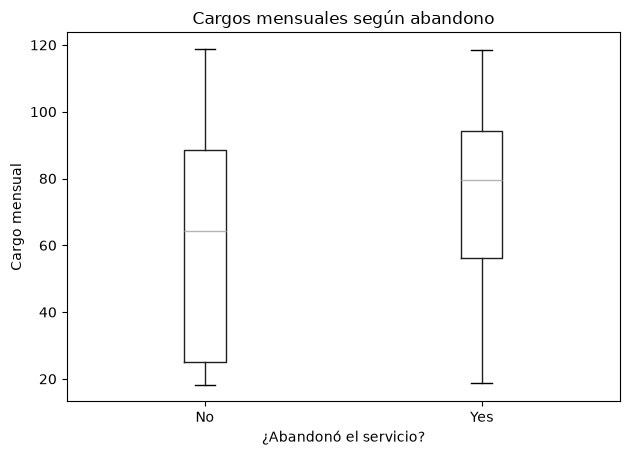

In [14]:
# Comparar cargos mensuales según abandono
resumen_cargos = (
    df_clean.groupby("Churn")
    .agg(
        Total_Clientes=("customerID", "count"),
        Cargo_Mensual_Promedio=("MonthlyCharges", "mean"),
        Cargo_Mensual_Mediano=("MonthlyCharges", "median")
    )
)

print("=== CARGOS MENSUALES SEGÚN ABANDONO ===")
display(resumen_cargos.round(2))

# Comparar distribuciones con un diagrama de caja
df_clean.boxplot(
    column="MonthlyCharges",
    by="Churn",
    grid=False
)

plt.title("Cargos mensuales según abandono")
plt.suptitle("")
plt.xlabel("¿Abandonó el servicio?")
plt.ylabel("Cargo mensual")
plt.tight_layout()
plt.show()

=== ABANDONO POR RANGO DE CARGOS MENSUALES ===


,MonthlyChargesGroup,Total_Clientes,Clientes_Abandonaron,Tasa_Abandono_%
0,$0-$30,1653,162,9.80
1,$30-$60,1265,328,25.93
2,$60-$90,2386,809,33.91
3,$90-$120,1739,570,32.78


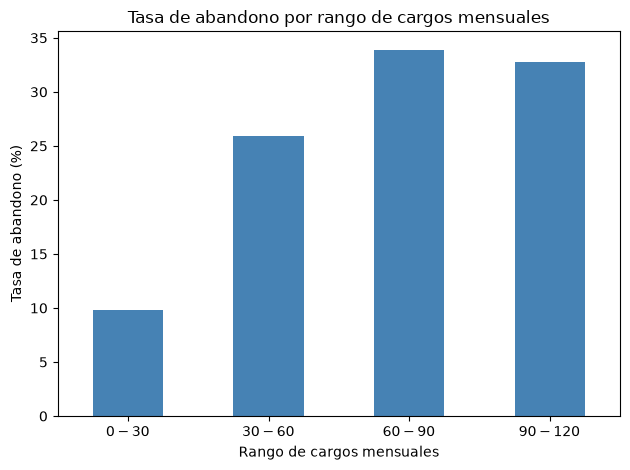

In [15]:
# Crear grupos de cargos mensuales
df_clean["MonthlyChargesGroup"] = pd.cut(
    df_clean["MonthlyCharges"],
    bins=[0, 30, 60, 90, 120],
    labels=[
        "$0-$30",
        "$30-$60",
        "$60-$90",
        "$90-$120"
    ],
    include_lowest=True
)

# Calcular clientes, abandonos y tasa por grupo
resumen_cargos = (
    df_clean.groupby("MonthlyChargesGroup", observed=False)
    .agg(
        Total_Clientes=("customerID", "count"),
        Clientes_Abandonaron=(
            "Churn",
            lambda grupo: (grupo == "Yes").sum()
        )
    )
    .reset_index()
)

resumen_cargos["Tasa_Abandono_%"] = (
    resumen_cargos["Clientes_Abandonaron"]
    / resumen_cargos["Total_Clientes"].replace(0, float("nan"))
    * 100
)

print("=== ABANDONO POR RANGO DE CARGOS MENSUALES ===")
display(resumen_cargos.round(2))

# Visualización para tu notebook
ax = resumen_cargos.set_index("MonthlyChargesGroup")[
    "Tasa_Abandono_%"
].plot(kind="bar", color="steelblue")

ax.set_title("Tasa de abandono por rango de cargos mensuales")
ax.set_xlabel("Rango de cargos mensuales")
ax.set_ylabel("Tasa de abandono (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [16]:
# Calcular la tasa de abandono por método de pago
churn_pago = (
    df_clean.groupby("PaymentMethod", observed=True)
    .agg(
        Total_Clientes=("customerID", "count"),
        Clientes_Abandonaron=(
            "Churn",
            lambda grupo: (grupo == "Yes").sum()
        )
    )
)

churn_pago["Tasa_Abandono_%"] = (
    churn_pago["Clientes_Abandonaron"]
    / churn_pago["Total_Clientes"]
    * 100
)

churn_pago = churn_pago.sort_values(
    "Tasa_Abandono_%",
    ascending=False
)

print("=== ABANDONO POR MÉTODO DE PAGO ===")
display(churn_pago.round(2))

=== ABANDONO POR MÉTODO DE PAGO ===


,Total_Clientes,Clientes_Abandonaron,Tasa_Abandono_%
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


In [17]:
# Calcular tasa de abandono por método de pago y contrato
tabla_pago_contrato = pd.pivot_table(
    df_clean,
    values="Churn",
    index="PaymentMethod",
    columns="Contract",
    aggfunc=lambda grupo: (grupo == "Yes").mean() * 100,
    observed=False
)

print("=== TASA DE ABANDONO: MÉTODO DE PAGO VS. CONTRATO (%) ===")
display(tabla_pago_contrato.round(2))

=== TASA DE ABANDONO: MÉTODO DE PAGO VS. CONTRATO (%) ===


Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),34.13,9.72,3.37
Credit card (automatic),32.78,10.30,2.24
Electronic check,53.73,18.44,7.74
Mailed check,31.58,6.82,0.79
